# Bakas: the plume that came when it didn't rain

*Every discharge leaves a bakas (trace). This notebook follows one.*

---

### The problem

Laguna de Bay feeds millions of people with fish and water. It is in trouble:

- **Fish catch roughly halved** between 2018 and 2022 (municipal fishing fell from about 64,000 to 32,500 metric tons).
- In 2023 the Laguna Lake Development Authority (LLDA) issued **924 Notices of Violation** and **9 Cease and Desist Orders** for water pollution, but **did not disclose who received them**.
- Lake water quality is reported **quarterly**, with gaps.
- In 2026 there were **three fish kills on the Rizal side of the lake**: Binangonan (July), Pililla (July 21) and Jala-jala (Sept 1, over 20,000 kg of fish). Fishers suspected wastewater. Regulators said it was too early to tell. **Nobody had the data.**

PFAS, pharmaceuticals and industrial chemicals are invisible from space. But they travel with discharge, and discharge is visible.

### The idea

Rain makes rivers muddy. That is expected. **A plume that appears when it has not rained for days is not.** Something else is pouring into the lake.

So Bakas asks three questions of every satellite pass:
1. Is any water near the shore a strange color compared with the open lake? (**OpenCV**)
2. Is it strange *for that spot*, compared with every other date? (**baseline**)
3. Did it rain? (**rainfall data**)

Run top to bottom: **Runtime > Run all** (about 5 minutes, no login or GPU).

In [1]:
import sys
if "google.colab" in sys.modules:
    !pip -q install pystac-client rasterio

In [2]:
import warnings; warnings.filterwarnings("ignore")
import json, subprocess, numpy as np, cv2, rasterio, matplotlib.pyplot as plt, matplotlib.dates as mdates
from datetime import datetime
from rasterio.warp import transform_bounds, transform as warp_xy
from rasterio.windows import from_bounds
from rasterio.enums import Resampling
from pystac_client import Client
from concurrent.futures import ThreadPoolExecutor

STAC = Client.open("https://earth-search.aws.element84.com/v1")   # Sentinel-2 on AWS Open Data
CLOUD_SCL = [3, 8, 9, 10]
print("OpenCV", cv2.__version__)

OpenCV 5.0.0


## Chapter 1: Two and a half years of the whole lake

We ran the Bakas pipeline over **every Sentinel-2 pass of Laguna de Bay from January 2024 to October 2026**: 980 images, 221 dates. Only **86 dates** had enough of the lake free of cloud to use.

The full scan takes about an hour, so its results are loaded here as a catalog. Each row is a plume Bakas detected, with the rainfall in the days before. Three detections were checked by eye and turned out to be haze or cloud edges; they are marked as artifacts and left out.

In [3]:
CATALOG = json.loads("[{\"date\": \"2024-02-11\", \"place\": \"Mabitac, Laguna\", \"lat\": 14.38143, \"lon\": 121.431, \"area_ha\": 38, \"kind\": \"dark\", \"rain_3d_mm\": 6.7, \"rain_7d_mm\": 10.2, \"dry\": false, \"artifact\": false}, {\"date\": \"2024-04-26\", \"place\": \"Cardona, Rizal\", \"lat\": 14.37583, \"lon\": 121.23779, \"area_ha\": 1237, \"kind\": \"dark\", \"rain_3d_mm\": 4.6, \"rain_7d_mm\": 4.6, \"dry\": true, \"artifact\": true}, {\"date\": \"2024-06-15\", \"place\": \"Bay, Laguna\", \"lat\": 14.20135, \"lon\": 121.29463, \"area_ha\": 87, \"kind\": \"brown+dark\", \"rain_3d_mm\": 35.2, \"rain_7d_mm\": 70.5, \"dry\": false, \"artifact\": false}, {\"date\": \"2025-03-07\", \"place\": \"Bi\\u00f1an, Laguna\", \"lat\": 14.36025, \"lon\": 121.09589, \"area_ha\": 155, \"kind\": \"brown\", \"rain_3d_mm\": 6.8, \"rain_7d_mm\": 8.8, \"dry\": false, \"artifact\": false}, {\"date\": \"2025-04-03\", \"place\": \"Cardona, Rizal\", \"lat\": 14.33479, \"lon\": 121.26041, \"area_ha\": 481, \"kind\": \"dark\", \"rain_3d_mm\": 0.9, \"rain_7d_mm\": 33.9, \"dry\": false, \"artifact\": true}, {\"date\": \"2025-04-23\", \"place\": \"Lumban, Laguna\", \"lat\": 14.34084, \"lon\": 121.42861, \"area_ha\": 76, \"kind\": \"dark\", \"rain_3d_mm\": 1.3, \"rain_7d_mm\": 2.1, \"dry\": true, \"artifact\": false}, {\"date\": \"2025-08-04\", \"place\": \"Paete, Laguna\", \"lat\": 14.35147, \"lon\": 121.47156, \"area_ha\": 1079, \"kind\": \"dark\", \"rain_3d_mm\": 0, \"rain_7d_mm\": 4.7, \"dry\": true, \"artifact\": false}, {\"date\": \"2025-08-19\", \"place\": \"Muntinlupa\", \"lat\": 14.46035, \"lon\": 121.0575, \"area_ha\": 765, \"kind\": \"dark\", \"rain_3d_mm\": 31.5, \"rain_7d_mm\": 64.2, \"dry\": false, \"artifact\": false}, {\"date\": \"2025-08-19\", \"place\": \"Taguig\", \"lat\": 14.50396, \"lon\": 121.07847, \"area_ha\": 71, \"kind\": \"dark\", \"rain_3d_mm\": 26.1, \"rain_7d_mm\": 62.3, \"dry\": false, \"artifact\": false}, {\"date\": \"2025-11-07\", \"place\": \"Victoria, Laguna\", \"lat\": 14.21745, \"lon\": 121.31092, \"area_ha\": 271, \"kind\": \"dark\", \"rain_3d_mm\": 21.0, \"rain_7d_mm\": 37.3, \"dry\": false, \"artifact\": false}, {\"date\": \"2025-11-07\", \"place\": \"Santa Rosa, Laguna\", \"lat\": 14.32018, \"lon\": 121.12186, \"area_ha\": 85, \"kind\": \"dark\", \"rain_3d_mm\": 17.4, \"rain_7d_mm\": 42.5, \"dry\": false, \"artifact\": false}, {\"date\": \"2025-11-29\", \"place\": \"Santa Cruz, Laguna\", \"lat\": 14.30496, \"lon\": 121.41219, \"area_ha\": 1853, \"kind\": \"dark\", \"rain_3d_mm\": 18.2, \"rain_7d_mm\": 66.2, \"dry\": false, \"artifact\": false}, {\"date\": \"2025-11-29\", \"place\": \"Lumban, Laguna\", \"lat\": 14.33745, \"lon\": 121.42294, \"area_ha\": 52, \"kind\": \"other\", \"rain_3d_mm\": 33.4, \"rain_7d_mm\": 150.1, \"dry\": false, \"artifact\": false}, {\"date\": \"2025-11-29\", \"place\": \"Kalayaan, Laguna\", \"lat\": 14.34841, \"lon\": 121.47745, \"area_ha\": 273, \"kind\": \"dark\", \"rain_3d_mm\": 33.4, \"rain_7d_mm\": 150.1, \"dry\": false, \"artifact\": false}, {\"date\": \"2025-11-29\", \"place\": \"Lumban, Laguna\", \"lat\": 14.33937, \"lon\": 121.44448, \"area_ha\": 363, \"kind\": \"dark\", \"rain_3d_mm\": 33.4, \"rain_7d_mm\": 150.1, \"dry\": false, \"artifact\": false}, {\"date\": \"2025-11-29\", \"place\": \"Baras, Rizal\", \"lat\": 14.50579, \"lon\": 121.26727, \"area_ha\": 46, \"kind\": \"dark\", \"rain_3d_mm\": 51.6, \"rain_7d_mm\": 81.5, \"dry\": false, \"artifact\": false}, {\"date\": \"2025-12-02\", \"place\": \"Bay, Laguna\", \"lat\": 14.19461, \"lon\": 121.28739, \"area_ha\": 52, \"kind\": \"dark\", \"rain_3d_mm\": 17.4, \"rain_7d_mm\": 69.2, \"dry\": false, \"artifact\": false}, {\"date\": \"2025-12-02\", \"place\": \"Santa Cruz, Laguna\", \"lat\": 14.29282, \"lon\": 121.39842, \"area_ha\": 158, \"kind\": \"dark\", \"rain_3d_mm\": 17.7, \"rain_7d_mm\": 55.3, \"dry\": false, \"artifact\": false}, {\"date\": \"2025-12-02\", \"place\": \"Lumban, Laguna\", \"lat\": 14.29642, \"lon\": 121.42575, \"area_ha\": 371, \"kind\": \"dark\", \"rain_3d_mm\": 17.7, \"rain_7d_mm\": 55.3, \"dry\": false, \"artifact\": false}, {\"date\": \"2025-12-02\", \"place\": \"Lumban, Laguna\", \"lat\": 14.31474, \"lon\": 121.43719, \"area_ha\": 33, \"kind\": \"dark\", \"rain_3d_mm\": 10.1, \"rain_7d_mm\": 85.6, \"dry\": false, \"artifact\": false}, {\"date\": \"2025-12-02\", \"place\": \"Pangil, Laguna\", \"lat\": 14.38453, \"lon\": 121.46396, \"area_ha\": 1029, \"kind\": \"dark\", \"rain_3d_mm\": 12.7, \"rain_7d_mm\": 72.6, \"dry\": false, \"artifact\": false}, {\"date\": \"2025-12-27\", \"place\": \"Pangil, Laguna\", \"lat\": 14.38758, \"lon\": 121.4607, \"area_ha\": 663, \"kind\": \"dark\", \"rain_3d_mm\": 7.8, \"rain_7d_mm\": 25.0, \"dry\": false, \"artifact\": false}, {\"date\": \"2026-03-07\", \"place\": \"Lumban, Laguna\", \"lat\": 14.30328, \"lon\": 121.42546, \"area_ha\": 62, \"kind\": \"other\", \"rain_3d_mm\": 0.1, \"rain_7d_mm\": 0.3, \"dry\": true, \"artifact\": false}, {\"date\": \"2026-03-07\", \"place\": \"Lumban, Laguna\", \"lat\": 14.32322, \"lon\": 121.43569, \"area_ha\": 337, \"kind\": \"dark\", \"rain_3d_mm\": 0.8, \"rain_7d_mm\": 6.7, \"dry\": true, \"artifact\": false}, {\"date\": \"2026-03-07\", \"place\": \"Lumban, Laguna\", \"lat\": 14.33294, \"lon\": 121.45454, \"area_ha\": 165, \"kind\": \"other\", \"rain_3d_mm\": 0.8, \"rain_7d_mm\": 6.7, \"dry\": true, \"artifact\": false}, {\"date\": \"2026-04-21\", \"place\": \"Pililla, Rizal\", \"lat\": 14.41964, \"lon\": 121.33499, \"area_ha\": 100, \"kind\": \"dark\", \"rain_3d_mm\": 0.4, \"rain_7d_mm\": 0.4, \"dry\": true, \"artifact\": true}, {\"date\": \"2026-05-06\", \"place\": \"Binangonan, Rizal\", \"lat\": 14.50436, \"lon\": 121.15458, \"area_ha\": 92, \"kind\": \"brown+dark\", \"rain_3d_mm\": 1.2, \"rain_7d_mm\": 1.4, \"dry\": true, \"artifact\": false}, {\"date\": \"2026-05-16\", \"place\": \"Calauan, Laguna\", \"lat\": 14.20163, \"lon\": 121.29574, \"area_ha\": 52, \"kind\": \"brown+dark\", \"rain_3d_mm\": 23.8, \"rain_7d_mm\": 24.6, \"dry\": false, \"artifact\": false}, {\"date\": \"2026-06-20\", \"place\": \"Cardona, Rizal\", \"lat\": 14.31469, \"lon\": 121.24424, \"area_ha\": 49, \"kind\": \"dark\", \"rain_3d_mm\": 11.1, \"rain_7d_mm\": 40.8, \"dry\": false, \"artifact\": false}, {\"date\": \"2026-07-05\", \"place\": \"Muntinlupa\", \"lat\": 14.43919, \"lon\": 121.05324, \"area_ha\": 36, \"kind\": \"dark\", \"rain_3d_mm\": 12.7, \"rain_7d_mm\": 54.0, \"dry\": false, \"artifact\": false}, {\"date\": \"2026-07-05\", \"place\": \"Taguig\", \"lat\": 14.47513, \"lon\": 121.062, \"area_ha\": 140, \"kind\": \"dark\", \"rain_3d_mm\": 12.7, \"rain_7d_mm\": 54.0, \"dry\": false, \"artifact\": false}, {\"date\": \"2026-09-23\", \"place\": \"Lumban, Laguna\", \"lat\": 14.32301, \"lon\": 121.43707, \"area_ha\": 348, \"kind\": \"brown+dark\", \"rain_3d_mm\": 34.8, \"rain_7d_mm\": 90.0, \"dry\": false, \"artifact\": false}, {\"date\": \"2026-09-25\", \"place\": \"San Pedro, Laguna\", \"lat\": 14.36439, \"lon\": 121.07193, \"area_ha\": 219, \"kind\": \"brown+dark\", \"rain_3d_mm\": 28.5, \"rain_7d_mm\": 60.3, \"dry\": false, \"artifact\": false}]")
real = [e for e in CATALOG if not e["artifact"]]
wet = [e for e in real if not e["dry"]]
dry = [e for e in real if e["dry"]]
print(f"Clear satellite passes scanned : 86")
print(f"Plumes detected                : {len(CATALOG)}  ({len(CATALOG) - len(real)} artifacts removed by visual check)")
print(f"Real plumes                    : {len(real)}")
print(f"  after rain (expected)        : {len(wet)}")
print(f"  with NO rain (suspicious)    : {len(dry)}")
print()
for e in dry:
    print(f"  {e['date']}  {e['place']:20s} {e['area_ha']:5d} ha   rain in prior 7 days: {e['rain_7d_mm']:.0f} mm")

Clear satellite passes scanned : 86
Plumes detected                : 33  (3 artifacts removed by visual check)
Real plumes                    : 30
  after rain (expected)        : 24
  with NO rain (suspicious)    : 6

  2025-04-23  Lumban, Laguna          76 ha   rain in prior 7 days: 2 mm
  2025-08-04  Paete, Laguna         1079 ha   rain in prior 7 days: 5 mm
  2026-03-07  Lumban, Laguna          62 ha   rain in prior 7 days: 0 mm
  2026-03-07  Lumban, Laguna         337 ha   rain in prior 7 days: 7 mm
  2026-03-07  Lumban, Laguna         165 ha   rain in prior 7 days: 7 mm
  2026-05-06  Binangonan, Rizal       92 ha   rain in prior 7 days: 1 mm


**Most plumes come after rain.** That is the common-sense part: storms wash the land into the rivers and the rivers into the lake.

**Six did not.** They sit in just two places: the **Lumban / Paete** corner in the southeast, and **Binangonan** in the north.

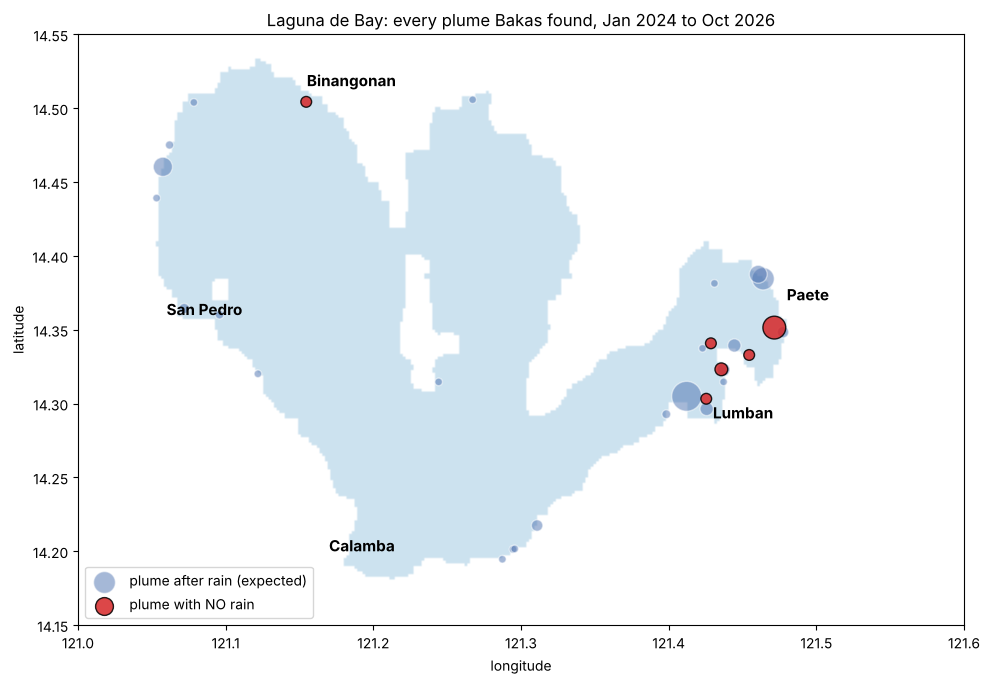

In [4]:
# Lake outline from one clear date (low resolution, quick)
LAKE_BBOX = (121.0, 14.15, 121.6, 14.55)
def scl_lowres(item, res_px=(220, 330)):
    with rasterio.open(item.assets["scl"].href) as src:
        b = transform_bounds("EPSG:4326", src.crs, *LAKE_BBOX)
        w = from_bounds(*b, transform=src.transform)
        return src.read(1, window=w, out_shape=res_px, boundless=True, fill_value=0, resampling=Resampling.nearest)
ids = ["S2A_51PTR_20241003_0_L2A", "S2A_51PUR_20241003_0_L2A", "S2A_51PTS_20241003_0_L2A", "S2A_51PUS_20241003_0_L2A"]
scl = np.zeros((220, 330), np.uint8)
for it in STAC.search(collections=["sentinel-2-l2a"], ids=ids).items():
    a = scl_lowres(it); scl[(scl == 0) & (a != 0)] = a[(scl == 0) & (a != 0)]
water = (scl == 6).astype(np.uint8)
n, lab, st, _ = cv2.connectedComponentsWithStats(water, 8)
lake = (lab == 1 + np.argmax(st[1:, cv2.CC_STAT_AREA])).astype(np.uint8)
lake = cv2.morphologyEx(lake, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))

fig, ax = plt.subplots(figsize=(10, 7))
ext = [LAKE_BBOX[0], LAKE_BBOX[2], LAKE_BBOX[1], LAKE_BBOX[3]]
ax.imshow(np.where(lake, 1.0, np.nan), extent=ext, cmap="Blues", vmin=0, vmax=3, alpha=0.6)
ax.scatter([e["lon"] for e in wet], [e["lat"] for e in wet], s=[max(30, e["area_ha"] / 4) for e in wet],
           c="#4c72b0", alpha=0.5, label="plume after rain (expected)", edgecolor="white")
ax.scatter([e["lon"] for e in dry], [e["lat"] for e in dry], s=[max(60, e["area_ha"] / 4) for e in dry],
           c="#d62728", alpha=0.85, label="plume with NO rain", edgecolor="black")
for name, (lo, la) in {"Binangonan": (121.155, 14.515), "Lumban": (121.43, 14.29), "Paete": (121.48, 14.37),
                       "Calamba": (121.17, 14.20), "San Pedro": (121.06, 14.36)}.items():
    ax.annotate(name, (lo, la), fontsize=11, weight="bold")
ax.set_title("Laguna de Bay: every plume Bakas found, Jan 2024 to Oct 2026")
ax.set_xlabel("longitude"); ax.set_ylabel("latitude"); ax.legend(loc="lower left")
plt.tight_layout(); plt.savefig("ch1_lake_map.png", dpi=130); plt.show()

The Lumban / Paete corner is the lake's busiest entry point, with plumes rain or shine. It is also where the **Pagsanjan River** and the outflow of the **Kalayaan hydropower plant** (which uses the lake as its lower reservoir) reach the lake, so dry-weather plumes there have a likely explanation.

**Binangonan has no such explanation.** So we zoom in.

## Chapter 2: Binangonan, dry season 2026

We now rerun the pipeline live, from scratch, on a small box off the Binangonan shore, for every clear pass since January 2025.

In [5]:
AOI   = (121.09, 14.44, 121.20, 14.53)                  # Binangonan shore and open water to the south-west
WATCH = (121.1330, 14.4967, 121.1566, 14.5092)          # the river mouth zone where the plume appears
DATES = "2025-01-01/2026-10-15"

def read(href, shape=None):
    with rasterio.open(href) as src:
        b = transform_bounds("EPSG:4326", src.crs, *AOI)
        w = from_bounds(*b, transform=src.transform)
        kw = {"window": w}
        if shape: kw["out_shape"] = shape
        out = src.read(1, **kw)
        tr = src.window_transform(w)
        if shape: tr = tr * tr.scale(w.width / shape[1], w.height / shape[0])
        return out, tr, src.crs

items = sorted(STAC.search(collections=["sentinel-2-l2a"], bbox=AOI, datetime=DATES, max_items=1000).items(), key=lambda i: i.datetime)
tile = max(set(i.id.split("_")[1] for i in items), key=lambda t: sum(i.id.split("_")[1] == t for i in items))
items = [i for i in items if i.id.split("_")[1] == tile]

def cloud_pct(it):
    s, _, _ = read(it.assets["scl"].href)
    return 100 * np.isin(s, CLOUD_SCL).mean()
with ThreadPoolExecutor(12) as ex:
    cp = list(ex.map(cloud_pct, items))
clear = [it for it, c in zip(items, cp) if c <= 25]
print(f"tile {tile}: {len(items)} passes, {len(clear)} clear enough")

def load(it):
    _, tr, crs = read(it.assets["visual"].href)
    with rasterio.open(it.assets["visual"].href) as src:
        b = transform_bounds("EPSG:4326", src.crs, *AOI); w = from_bounds(*b, transform=src.transform)
        rgb = np.transpose(src.read(window=w), (1, 2, 0))
    h, wd = rgb.shape[:2]
    off = 0.0 if it.properties.get("earthsearch:boa_offset_applied", False) else -0.1
    s = {"date": it.datetime.strftime("%Y-%m-%d"), "rgb": rgb, "tr": tr, "crs": crs}
    s["scl"] = read(it.assets["scl"].href, (h, wd))[0]
    for k in ["blue", "green", "red", "swir16"]:
        s[k] = read(it.assets[k].href, (h, wd))[0].astype("float32") * 1e-4 + off
    return s
with ThreadPoolExecutor(8) as ex:
    scenes = list(ex.map(load, clear))
print("loaded", len(scenes), "scenes")

tile 51PTS: 162 passes, 43 clear enough


loaded 43 scenes


### The OpenCV pipeline
1. **Water mask:** MNDWI (green vs. SWIR) because the lake is too green with algae for the usual index; `morphologyEx` cleans it; `connectedComponentsWithStats` keeps only the lake.
2. **Color distance:** Mahalanobis distance of each pixel's color (red/green, blue/green, brightness) from the open lake more than 1.5 km offshore.
3. **Texture filter:** local roughness via `cv2.blur` removes sun glint and wave speckle.
4. **Baseline:** for every pixel, the median color distance across all dates. A plume must be unusual *for that spot*.

In [6]:
def smooth_nan(x, s=2):
    m = np.isfinite(x).astype("float32"); v = np.nan_to_num(x).astype("float32")
    o = cv2.GaussianBlur(v, (0, 0), s) / np.maximum(cv2.GaussianBlur(m, (0, 0), s), 1e-3); o[m == 0] = np.nan; return o

def analyze(s):
    r, g, b, sw = [np.clip(s[k], 1e-3, None) for k in ["red", "green", "blue", "swir16"]]
    cloud = cv2.dilate(np.isin(s["scl"], CLOUD_SCL).astype(np.uint8), np.ones((31, 31), np.uint8)) > 0
    w = ((((g - sw) / (g + sw)) > 0) & ~cloud).astype(np.uint8) * 255
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    w = cv2.morphologyEx(cv2.morphologyEx(w, cv2.MORPH_OPEN, k), cv2.MORPH_CLOSE, k)
    n, lab, st, _ = cv2.connectedComponentsWithStats(w, 8)
    if n < 2: s["D"] = np.full(g.shape, np.nan, "float32"); return s
    lake = (lab == 1 + np.argmax(st[1:, cv2.CC_STAT_AREA])).astype(np.uint8) * 255
    shore = cv2.distanceTransform(lake, cv2.DIST_L2, 5)
    lg = np.log(g).astype("float32"); mu = cv2.blur(lg, (7, 7))
    rough = np.sqrt(np.clip(cv2.blur(lg * lg, (7, 7)) - mu * mu, 0, None))
    ok = (lake > 0) & (shore > 3) & (rough < np.percentile(rough[lake > 0], 95))
    ref = ok & (shore > 150)
    if ref.sum() < 3000: ref = ok
    F = np.stack([np.log(r / g), np.log(b / g), lg], -1)
    m0 = np.median(F[ref], 0); inv = np.linalg.inv(np.cov((F[ref] - m0).T) + np.eye(3) * 1e-6)
    d = F - m0
    s["D"] = smooth_nan(np.where(ok, np.sqrt(np.einsum("...i,ij,...j->...", d, inv, d)), np.nan))
    return s

with ThreadPoolExecutor(4) as ex:
    scenes = list(ex.map(analyze, scenes))
shape = min(s["D"].shape for s in scenes)
for s in scenes:
    s["D"] = s["D"][:shape[0], :shape[1]]
base = np.nanmedian(np.stack([s["D"] for s in scenes]), 0)

# pixel box for the watch zone
s0 = scenes[0]
xs, ys = warp_xy("EPSG:4326", s0["crs"], [WATCH[0], WATCH[2]], [WATCH[3], WATCH[1]])
(c0, r0), (c1, r1) = [~s0["tr"] * (x, y) for x, y in zip(xs, ys)]
r0, r1, c0, c1 = int(r0), int(r1), int(c0), int(c1)

for s in scenes:
    ch = (s["D"] - base)[r0:r1, c0:c1]
    s["valid"] = float(np.isfinite(ch).mean())
    s["anomaly"] = float(np.nanmean(ch > 3)) * 100 if s["valid"] > 0.3 else np.nan
print("done")

done


### Rain vs. plume
Rainfall for Binangonan from the Open-Meteo historical archive.

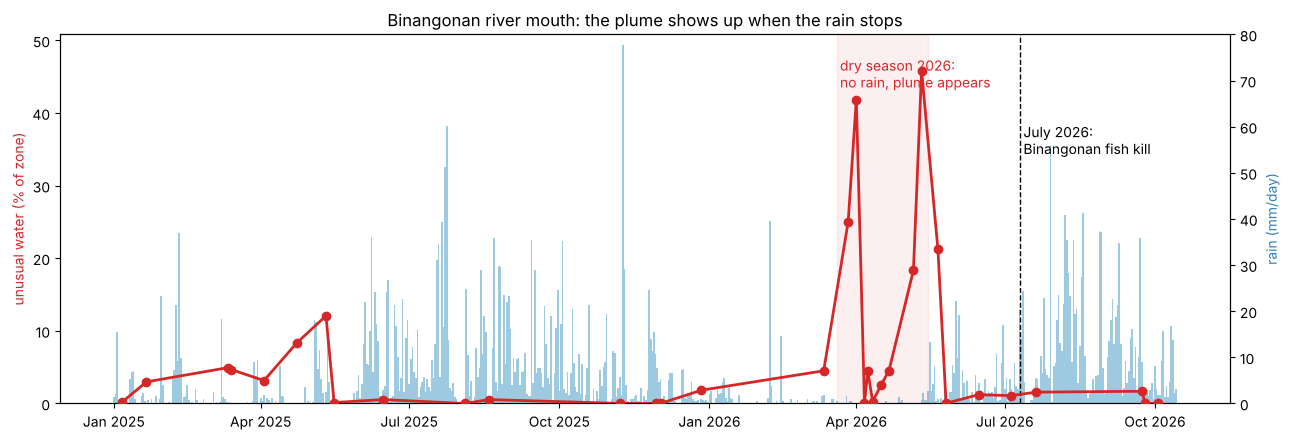

date        unusual  rain(7d)
2025-01-06      0%      20 mm
2025-01-21      3%       6 mm
2025-03-12      5%      22 mm
2025-03-14      5%      22 mm
2025-04-03      3%      29 mm
2025-04-23      8%       0 mm
2025-05-11     12%      65 mm
2025-05-16      0%      28 mm
2025-06-15      1%     103 mm
2025-08-04      0%       7 mm
2025-08-19      1%      90 mm
2025-11-07      0%      34 mm
2025-11-29      0%      82 mm
2025-12-02      0%      94 mm
2025-12-27      2%      10 mm
2026-03-12      5%       5 mm
2026-03-27     25%       3 mm
2026-04-01     42%       3 mm
2026-04-06      0%       0 mm
2026-04-08      4%       0 mm
2026-04-11      0%       0 mm
2026-04-16      2%       0 mm
2026-04-21      5%       1 mm
2026-05-06     18%       1 mm
2026-05-11     46%       1 mm
2026-05-21     21%      34 mm
2026-05-26      0%      15 mm
2026-06-15      1%      22 mm
2026-07-05      1%      44 mm
2026-07-20      2%      14 mm
2026-09-23      2%     105 mm
2026-09-25      0%      81 mm
2026-10-03

In [7]:
url = ("https://archive-api.open-meteo.com/v1/archive?latitude=14.50&longitude=121.16"
       "&start_date=2025-01-01&end_date=2026-10-14&daily=precipitation_sum&timezone=Asia%2FManila")
try:
    import urllib.request; rain = json.load(urllib.request.urlopen(url, timeout=60))["daily"]
except Exception:
    rain = json.loads(subprocess.run(["curl", "-sS", url], capture_output=True, text=True).stdout)["daily"]
rain_t = [datetime.fromisoformat(t) for t in rain["time"]]
rain_p = np.array([p or 0 for p in rain["precipitation_sum"]])
def rain7(date):
    i = rain["time"].index(date); return float(rain_p[max(0, i - 7):i + 1].sum())
for s in scenes: s["rain7"] = rain7(s["date"])

ok = [s for s in scenes if np.isfinite(s["anomaly"])]
fig, ax = plt.subplots(figsize=(13, 4.5))
ax2 = ax.twinx()
ax2.bar(rain_t, rain_p, color="#9ecae1", width=1.0, label="daily rain (mm)")
ax2.set_ylabel("rain (mm/day)", color="#3182bd"); ax2.set_ylim(0, max(80, rain_p.max()))
t = [datetime.fromisoformat(s["date"]) for s in ok]; a = [s["anomaly"] for s in ok]
ax.plot(t, a, "-o", color="#d62728", lw=2, zorder=5, label="unusual water at the river mouth (% of zone)")
ax.set_zorder(ax2.get_zorder() + 1); ax.patch.set_visible(False)
ax.set_ylabel("unusual water (% of zone)", color="#d62728"); ax.set_ylim(0, max(35, max(a) + 5))
ax.axvspan(datetime(2026, 3, 20), datetime(2026, 5, 15), color="#d62728", alpha=0.07)
ax.annotate("dry season 2026:\nno rain, plume appears", (datetime(2026, 3, 22), max(a) * 0.95), fontsize=10, color="#d62728")
ax.axvline(datetime(2026, 7, 10), color="black", ls="--", lw=1)
ax.annotate(" July 2026:\n Binangonan fish kill", (datetime(2026, 7, 10), max(a) * 0.75), fontsize=10)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set_title("Binangonan river mouth: the plume shows up when the rain stops")
plt.tight_layout(); plt.savefig("ch2_rain_vs_plume.png", dpi=130); plt.show()

print("date        unusual  rain(7d)")
for s in ok: print(f"{s['date']}  {s['anomaly']:5.0f}%  {s['rain7']:6.0f} mm")

**This is the bakas.** From late March to mid-May 2026 almost no rain fell on Binangonan. If the river carried only rainwater, its mouth should have been at its calmest. Instead, unusual water kept showing up there, on some passes covering close to half the zone. In the rainy months it almost never appears.

A plume that **comes when the rain stops** is what you expect when something other than rain feeds the river: a discharge that rainwater normally dilutes.

In [8]:
dry_p = [s for s in ok if s["rain7"] < 10]
wet_p = [s for s in ok if s["rain7"] >= 30]
season = [s for s in ok if "2026-03-20" <= s["date"] <= "2026-05-15"]
print(f"Average unusual water, dry passes (<10 mm rain in 7 days): {np.mean([s['anomaly'] for s in dry_p]):4.1f}%  ({len(dry_p)} passes)")
print(f"Average unusual water, wet passes (>=30 mm)              : {np.mean([s['anomaly'] for s in wet_p]):4.1f}%  ({len(wet_p)} passes)")
print(f"Dry season 2026: plume on {sum(s['anomaly'] > 10 for s in season)} of {len(season)} clear passes, peak {max(s['anomaly'] for s in season):.0f}% of zone")

Average unusual water, dry passes (<10 mm rain in 7 days): 12.2%  (13 passes)
Average unusual water, wet passes (>=30 mm)              :  3.7%  (10 passes)
Dry season 2026: plume on 4 of 9 clear passes, peak 46% of zone


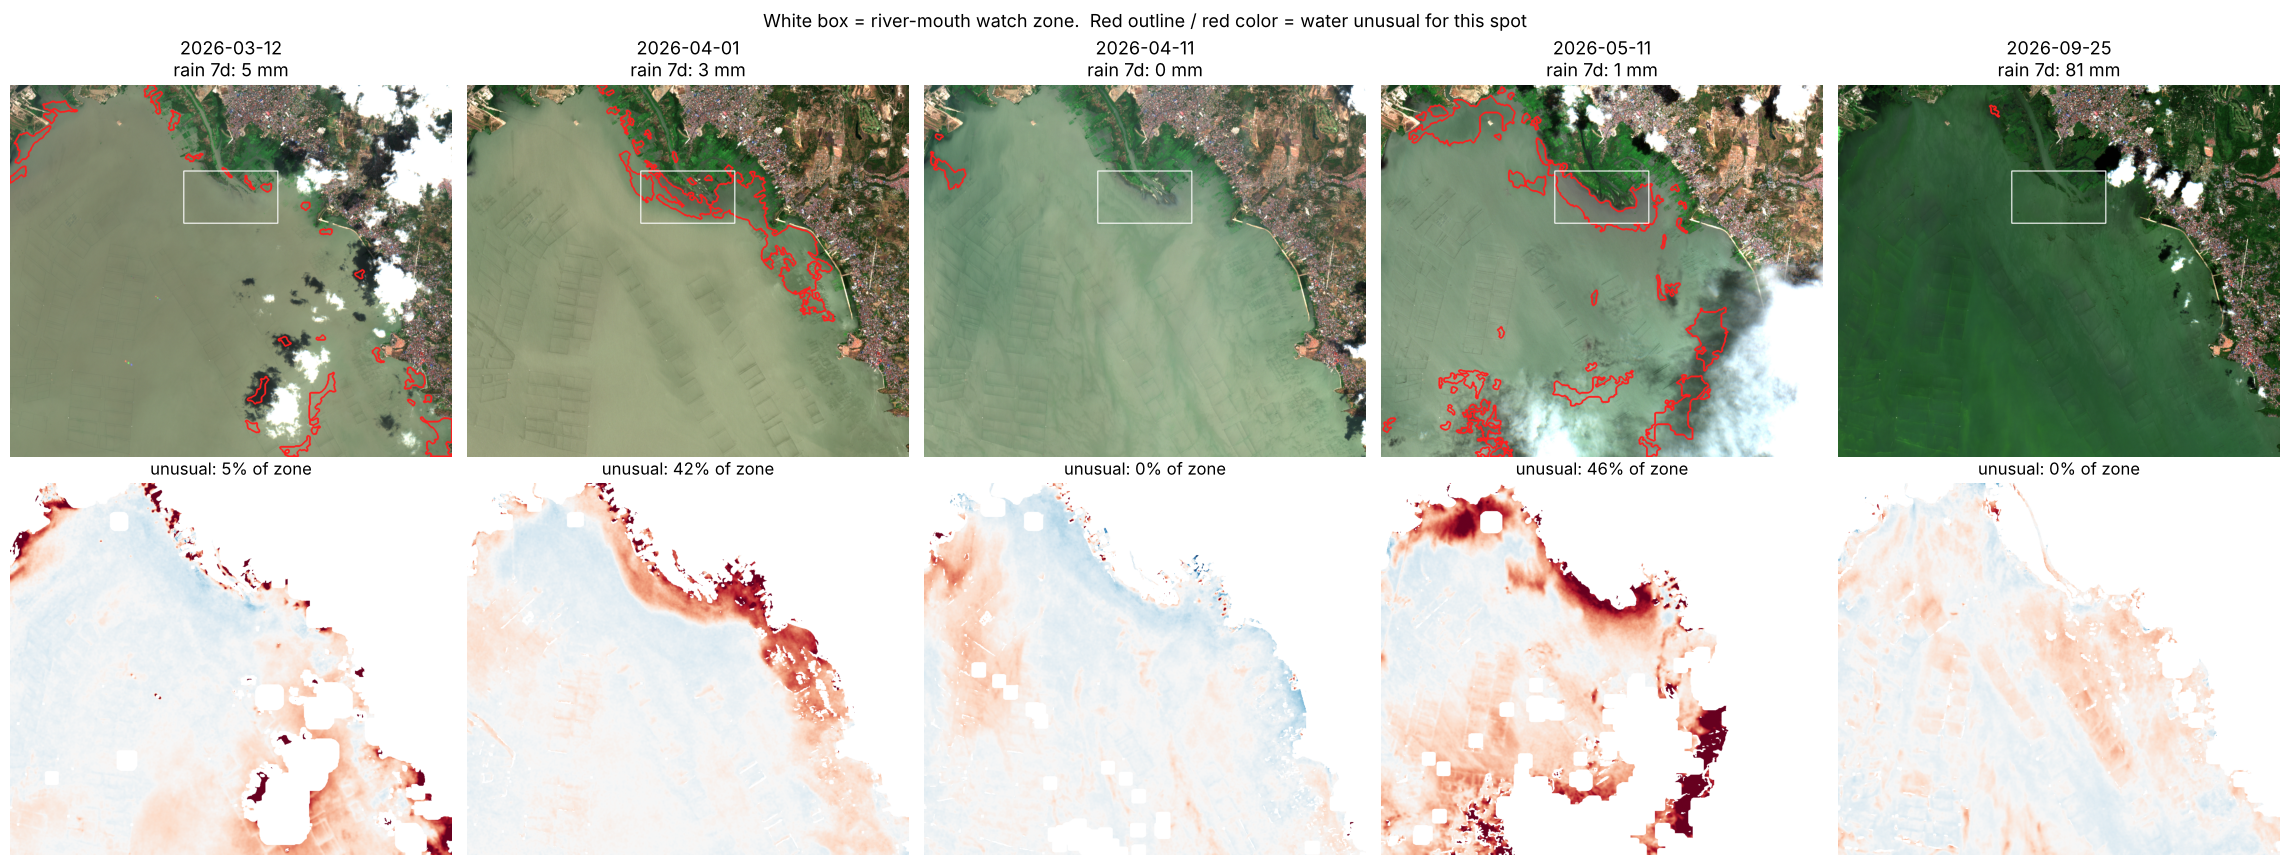

In [9]:
pick = [s for s in ok if s["date"] in ("2026-03-12", "2026-04-01", "2026-04-11", "2026-05-11", "2026-09-25")]
fig, axs = plt.subplots(2, len(pick), figsize=(4.6 * len(pick), 9))
for i, s in enumerate(pick):
    img = s["rgb"][:shape[0], :shape[1]].copy()
    ch = s["D"] - base
    m = (np.nan_to_num(ch) > 3).astype(np.uint8) * 255
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5)))
    cs = [c for c in cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[0] if cv2.contourArea(c) > 150]
    cv2.drawContours(img, cs, -1, (255, 30, 30), 3)
    cv2.rectangle(img, (c0, r0), (c1, r1), (255, 255, 255), 2)
    axs[0, i].imshow(img); axs[0, i].set_title(f"{s['date']}\nrain 7d: {s['rain7']:.0f} mm", fontsize=13)
    axs[1, i].imshow(ch, cmap="RdBu_r", vmin=-8, vmax=8); axs[1, i].set_title(f"unusual: {s['anomaly']:.0f}% of zone")
    for a in axs[:, i]: a.axis("off")
plt.suptitle("White box = river-mouth watch zone.  Red outline / red color = water unusual for this spot", fontsize=13)
plt.tight_layout(); plt.savefig("ch2_strip.png", dpi=110); plt.show()

**But look closely before you accuse anyone.** On April 1 and May 11 the unusual water hugs a long stretch of shoreline, not only the river mouth. In the dry season the lake level drops and the shallows can change color (exposed bottom, stirred mud, floating plants), which can look like a plume. So this is **a lead, not a verdict**: a place and a season where a field team should go and take samples. That is exactly what Bakas is for.

## Chapter 3: What happened next

- **July 2026:** fish kill in **Binangonan**, the first of three on the Rizal side that year. The LLDA said it was too early to determine a cause and pointed to an algal bloom.
- **July 21:** fish kill off Pililla.
- **Sept 1:** over 20,000 kg of tilapia and bighead carp dead in Jala-jala. Fishers said the water had turned "rusty" and blamed wastewater.

**We cannot say the Binangonan plume caused the fish kill.** The plume was months earlier, and fish kills have many causes (algae, heat, low oxygen). What we can say:

> In the months before the fish kill, unusual water kept entering the lake off Binangonan on days with no rain, and no one was sampling it.

That is the gap Bakas closes. Here is the alert Bakas would have sent the LLDA in May 2026:

In [10]:
season = [x for x in ok if "2026-03-20" <= x["date"] <= "2026-05-15"]
s = max(season, key=lambda x: x["anomaly"])
ch = (s["D"] - base)[r0:r1, c0:c1]
yy, xx = np.where(np.nan_to_num(ch) > 3)
cx, cy = c0 + xx.mean(), r0 + yy.mean()
X, Y = s["tr"] * (cx, cy); lon, lat = warp_xy(s["crs"], "EPSG:4326", [X], [Y]); lon, lat = lon[0], lat[0]
hits = [x["date"] for x in season if x["anomaly"] > 10]
print(f"BAKAS ALERT  |  {s['date']}  |  Binangonan, Rizal")
print("-" * 60)
print(f"Type        : dry-weather plume (rain in prior 7 days: {s['rain7']:.0f} mm)")
print(f"Recurrence  : seen on {len(hits)} of {len(season)} clear passes since late March: {', '.join(hits)}")
print(f"Size        : {s['anomaly']:.0f}% of the river-mouth zone (average on rainy passes: {np.mean([x['anomaly'] for x in ok if x['rain7'] >= 30]):.0f}%)")
print(f"Sample at   : {lat:.5f}, {lon:.5f}   https://maps.google.com/?q={lat:.5f},{lon:.5f}")
print("Action      : field check; sample the river mouth, 500 m upstream and the nearby shallows; test for")
print("              nutrients, BOD, ammonia, and PFAS / emerging contaminants.")

BAKAS ALERT  |  2026-05-11  |  Binangonan, Rizal
------------------------------------------------------------
Type        : dry-weather plume (rain in prior 7 days: 1 mm)
Recurrence  : seen on 4 of 9 clear passes since late March: 2026-03-27, 2026-04-01, 2026-05-06, 2026-05-11
Size        : 46% of the river-mouth zone (average on rainy passes: 4%)
Sample at   : 14.50162, 121.14496   https://maps.google.com/?q=14.50162,121.14496
Action      : field check; sample the river mouth, 500 m upstream and the nearby shallows; test for
              nutrients, BOD, ammonia, and PFAS / emerging contaminants.


## Chapter 4: Why this needs a system, not common sense

| | Common sense | Existing satellite maps | **Bakas** |
|---|---|---|---|
| "Rain makes rivers muddy" | yes | yes | yes |
| Knows what is **normal for each spot** | no | no | **yes** (per-pixel baseline) |
| Separates rain plumes from **dry-weather plumes** | no | no | **yes** (rainfall check) |
| Tells you **where and when to sample** | no | no | **yes** |
| Runs on every pass, automatically | no | partly | **yes** (AWS) |

Out of 86 clear passes and 30 real plumes over 2.5 years, Bakas narrowed the whole lake down to **two places** worth a field team's limited time, and found a likely innocent explanation for one of them. That is the job: turn free images into a short list a regulator can act on.

### Limits, stated plainly
- A plume is a **pathway, not proof**. Only lab tests confirm what is in the water.
- **Clouds:** only 86 of 221 dates were usable. Radar (Sentinel-1) is the next step for cloudy weeks.
- **Rainfall** comes from a weather model (Open-Meteo archive), not a local rain gauge.
- Dry-weather plumes can have innocent causes (dredging, hydropower releases, irrigation return flow). Bakas flags; people verify.
- The Binangonan plume and the July fish kill are **months apart**. We show them together as context, not cause.

### Sources
- Inquirer.net, *Accountability adrift: murky gov't data draw dreary picture of Laguna Lake* (May 23, 2024): NOV/CDO counts, fish catch, quarterly data.
- The Star / Khaleej Times, *Over 20,000 kg of fish die in latest Laguna de Bay fish kill* (Sept 1, 2026): Jala-jala fish kill, earlier Binangonan fish kill in July.
- Inquirer.net, *LLDA probes Laguna de Bay fish kill* (July 14, 2026).
- Inquirer.net, *PCG, BFAR probe fish kill in Pililla waters* (July 23, 2026).
- Wikipedia, *Caliraya Dam*: Kalayaan pumped storage uses Laguna de Bay as its lower reservoir.
- Sentinel-2 L2A via Element 84 Earth Search on AWS Open Data; rainfall via Open-Meteo Historical Weather API.